In [1]:
import pandas as pd
df = pd.read_csv("massey_ratings.csv")
display(df.head())

,Team,Conference,Record,Win Pct,Rank 1,Detail 1,Rank 2,Detail 2,Rank 3,Detail 3,Rank 4,Detail 4,Rank 5,Detail 5,Rank 6,Detail 6,Year,Rank 7,Detail 7
0,Notre Dame,Eastern Ind,Oct-00,1.000,1,9.55,1,45.39,1,39.33,6,19.28,3.07,NaN,6,30.53,1924,NaN,NaN
1,West Virginia,Eastern Ind,1-Aug,0.889,2,9.04,2,43.07,2,38.50,14,17.79,3.21,NaN,14,25.81,1924,NaN,NaN
2,Illinois,Western,6/1/01,0.813,3,8.84,3,38.78,3,35.45,27,16.55,3.14,NaN,7,28.57,1924,NaN,NaN
3,California,PCC,8-0-2,0.900,4,8.80,5,36.83,19,29.12,2,20.92,3.21,NaN,19,25.15,1924,NaN,NaN
4,Dartmouth,NE Independent,7-0-1,0.938,5,8.70,15,33.37,10,30.85,32,15.74,3.06,NaN,53,20.62,1924,NaN,NaN


In [2]:
# 2. View the first few rows (default is 5 rows)
print("--- First 5 rows ---")
print(df.head())

# 3. View the last few rows (default is 5 rows)
print("\n--- Last 5 rows ---")
print(df.tail())

# 4. View a random sample of rows (e.g., 5 random rows)
print("\n--- Random sample of 5 rows ---")
print(df.sample(5))

# 5. View a concise summary of the DataFrame (column names, data types, non-null counts)
print("\n--- DataFrame Information ---")
df.info()

# 6. View basic descriptive statistics for numerical columns (mean, min, max, percentiles)
print("\n--- Descriptive Statistics ---")
print(df.describe())

# 7. View the dimensions of the dataset (number of rows and columns)
print("\n--- Shape of the DataFrame (Rows, Columns) ---")
print(df.shape)

# Rename "Detail 2" column
df.rename(columns={'Detail 2': 'Power'}, inplace=True)
# 8. View all the column names
print("\n--- Column Names ---")
print(df.columns.tolist())

--- First 5 rows ---
            Team      Conference  Record  Win Pct  Rank 1  Detail 1  Rank 2  \
0     Notre Dame     Eastern Ind  Oct-00    1.000       1      9.55       1   
1  West Virginia     Eastern Ind   1-Aug    0.889       2      9.04       2   
2       Illinois         Western  6/1/01    0.813       3      8.84       3   
3     California             PCC   8-0-2    0.900       4      8.80       5   
4      Dartmouth  NE Independent   7-0-1    0.938       5      8.70      15   

   Detail 2  Rank 3  Detail 3  Rank 4  Detail 4  Rank 5  Detail 5  Rank 6  \
0     45.39       1     39.33       6     19.28    3.07       NaN       6   
1     43.07       2     38.50      14     17.79    3.21       NaN      14   
2     38.78       3     35.45      27     16.55    3.14       NaN       7   
3     36.83      19     29.12       2     20.92    3.21       NaN      19   
4     33.37      10     30.85      32     15.74    3.06       NaN      53   

   Detail 6  Year  Rank 7  Detail 7  
0  

In [3]:
# Select specific columns and view the first 5 rows
subset_df = df[['Team', 'Power', 'Year']]
display(subset_df.head())

,Team,Power,Year
0,Notre Dame,45.39,1924
1,West Virginia,43.07,1924
2,Illinois,38.78,1924
3,California,36.83,1924
4,Dartmouth,33.37,1924


In [4]:
# Pivot the data to create a time series
time_series_df = df.pivot_table(
    index='Team', 
    columns='Year', 
    values='Power'
)

# View the first few rows of the new time series
display(time_series_df.head())

Year,1924,1925,1926,1927,1928,1929,1930,1931,1932,1933,...,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
Team,,,,,,,,,,,,,,,,,,,,,
1st Infantry,NaN,NaN,NaN,NaN,NaN,NaN,-24.77,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
20th Infantry,NaN,NaN,NaN,NaN,NaN,NaN,-25.29,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
260 Coast Art.,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2nd Air Force CO,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2nd Air Force WA,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [5]:
# Drop any row (team) that has NaN values in any of the columns (years)
clean_time_series = time_series_df.dropna()

# View the cleaned time series
display(clean_time_series.head())

# See how many rows you have left compared to the original
print(f"Original number of teams: {len(time_series_df)}")
print(f"Number of teams after dropping NaNs: {len(clean_time_series)}")

Year,1924,1925,1926,1927,1928,1929,1930,1931,1932,1933,...,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
Team,,,,,,,,,,,,,,,,,,,,,
Arkansas,16.81,14.80,24.61,26.78,32.86,34.07,23.76,19.12,21.38,30.22,...,65.58,56.35,51.92,52.96,51.50,56.99,64.43,64.65,58.49,61.34
Army,32.90,30.83,32.41,33.69,34.50,33.50,37.09,37.63,40.60,35.75,...,35.65,43.48,49.53,58.21,52.00,54.45,57.98,54.73,48.92,56.54
Boston College,28.59,26.28,31.37,20.52,32.70,26.78,26.39,26.15,22.59,24.23,...,49.95,48.57,58.16,62.18,55.94,55.71,55.48,50.75,51.34,56.16
California,36.83,38.73,27.33,31.91,37.38,40.31,27.96,36.39,36.91,37.38,...,60.23,54.46,54.98,58.52,60.22,58.38,58.75,56.77,58.33,55.91
Clemson,4.12,-0.82,-6.52,5.47,15.93,18.42,24.23,9.67,14.27,14.11,...,68.67,75.42,77.03,87.17,86.68,80.52,74.40,73.23,67.92,66.91


Original number of teams: 1016
Number of teams after dropping NaNs: 49


In [6]:
# 1. Identify all the columns (years) that are after 1950
# Change to >= 1950 if you want to include 1950 itself
years_after_2000 = [year for year in time_series_df.columns if int(year) > 2000]

# 2. Drop rows (teams) that have NaN values specifically in those later years
clean_time_series_post_2000 = time_series_df.dropna(subset=years_after_2000)

# View the result
display(clean_time_series_post_2000.head())

# See how many rows you have left compared to the original
print(f"Original number of teams: {len(time_series_df)}")
print(f"Number of teams after dropping post-2000 NaNs: {len(clean_time_series_post_2000)}")

Year,1924,1925,1926,1927,1928,1929,1930,1931,1932,1933,...,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
Team,,,,,,,,,,,,,,,,,,,,,
Air Force,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,50.32,50.20,46.96,53.69,61.72,59.15,61.98,60.92,56.29,48.75
Akron,5.10,-2.07,2.43,-4.17,-6.90,4.85,5.04,-0.19,-8.96,-2.91,...,41.11,36.94,37.77,40.51,28.23,28.18,30.34,35.51,31.84,34.27
Alabama,33.35,37.66,37.80,30.58,34.35,37.26,50.33,48.20,40.51,38.17,...,76.21,80.34,80.09,86.36,86.19,90.44,85.12,85.75,80.59,77.16
Arizona,4.86,5.67,7.19,7.92,4.04,11.10,12.45,5.01,3.26,14.58,...,55.05,46.44,54.75,56.41,53.29,48.93,47.67,53.04,64.73,52.06
Arizona St,NaN,-17.31,NaN,-16.45,-18.10,-14.23,-8.61,-0.42,0.48,3.57,...,57.59,50.70,55.74,60.90,60.47,63.72,63.99,56.95,52.99,63.71


Original number of teams: 1016
Number of teams after dropping post-2000 NaNs: 113


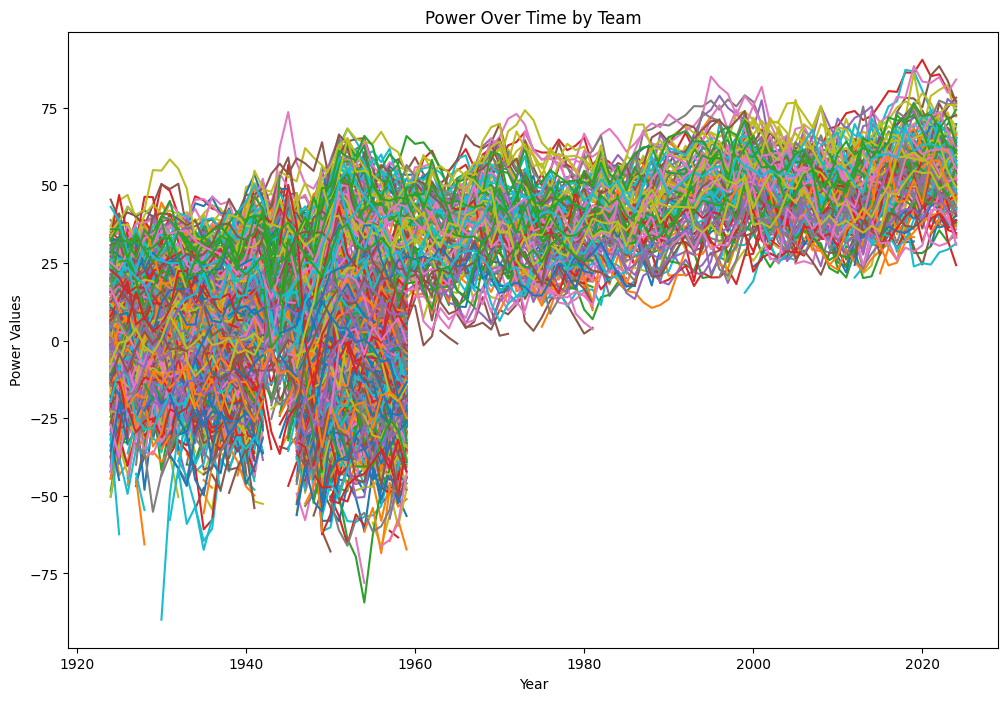

In [7]:
import matplotlib.pyplot as plt

# Set the size of the plot to make it readable
plt.figure(figsize=(12, 8))

# Plot the data
# .T transposes the DataFrame so years (columns) become the x-axis 
# and teams (rows) become the individual lines
plt.plot(time_series_df.T)

# Add titles and labels
plt.title('Power Over Time by Team')
plt.xlabel('Year')
plt.ylabel('Power Values')

# Display the plot
plt.show()

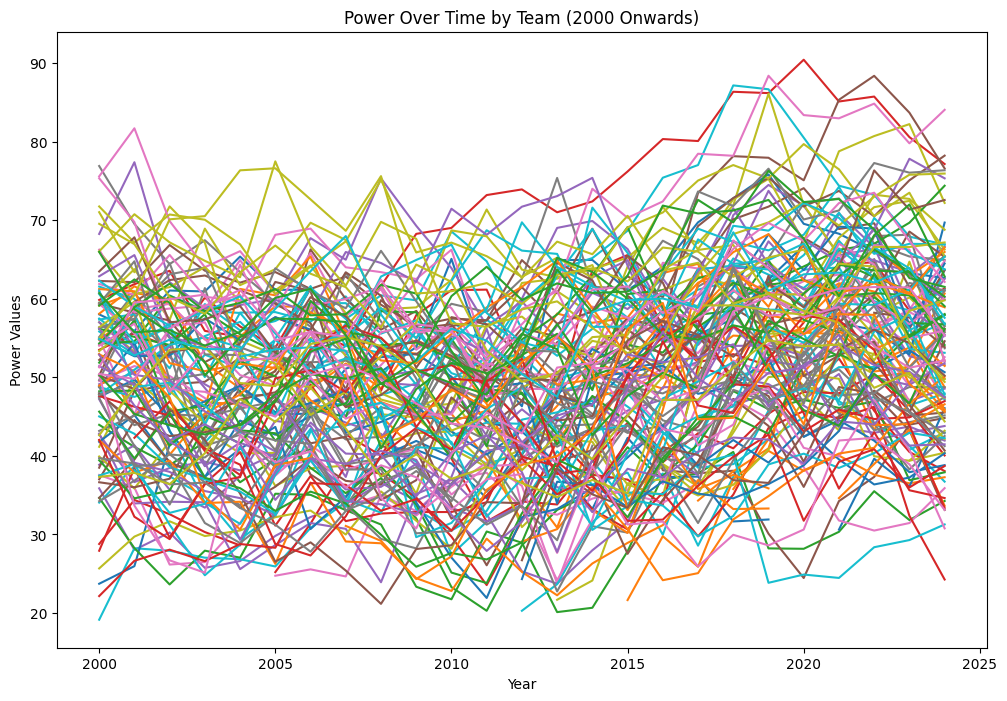

In [8]:
import matplotlib.pyplot as plt

# 1. Identify all the columns (years) that are 2000 or later
years_from_2000 = [year for year in time_series_df.columns if int(year) >= 2000]

# 2. Filter the DataFrame to only include those years
time_series_2000s = time_series_df[years_from_2000]

# 3. Set the size of the plot
plt.figure(figsize=(12, 8))

# 4. Transpose (.T) and plot the filtered data
plt.plot(time_series_2000s.T)

# 5. Add titles and labels
plt.title('Power Over Time by Team (2000 Onwards)')
plt.xlabel('Year')
plt.ylabel('Power Values')

# Display the plot
plt.show()

In [8]:
import pandas as pd



# Identify columns strictly after 2000
years_after_2000 = [year for year in time_series_df.columns if int(year) > 2000]
df_post_2000 = time_series_df[years_after_2000]

# Find teams that have at least one NaN in these years and convert to a list
teams_with_nan = df_post_2000[df_post_2000.isna().any(axis=1)].index.tolist()

# Print the list of teams
print(f"Number of teams: {len(teams_with_nan)}")
print(", ".join(teams_with_nan))

# teams without nans
print(f"Number of teams: {len(df_post_2000)-len(df_post_2000[df_post_2000.isna().any(axis=1)].index.tolist())}")


Number of teams: 903
1st Infantry, 20th Infantry, 260 Coast Art., 2nd Air Force CO, 2nd Air Force WA, AZ All-Stars, Abilene Chr, Abilene Field, Adams St, Adelphi, Adrian, Alabama A&M, Alabama St, Alameda C Guard, Alameda NAS, Albany GA, Albion, Albright, Albuq Field, Alcorn St, Alfred, Allegheny, Allen, Alliance, Alma, Amarillo Field, American Intl, American Univ, Amherst, Anaconda Anodes, Anderson IN, Antelope Val CC, Antioch, Appalachian St, Apprentice, Ark Baptist, Ark Monticello, Ark Pine Bluff, Arkansas Tech, Ashland, Athens St, Atl. City NAS, Augsburg, Augustana SD, Austin Col, Austin Peay, Bainbridge NTS, Baker KS, Baldwin-Wallace, Baltimore, Barksdale AFB, Barksdale Field, Bates, Beaumont Hosp., Belmont Abbey, Beloit, Bemidji St, Benedict, Benedictine KS, Berg Field, Bergstrom Field, Bethany KS, Bethany WV, Bethel KS, Bethel MN, Bethel TN, Bethune-Cookman, Birmingham So, Bishop, Black Hills St, Blackburn, Blackland Field, Bloomsburg, Bluefield St, Bluefield Univ, Bluffton, Bogu

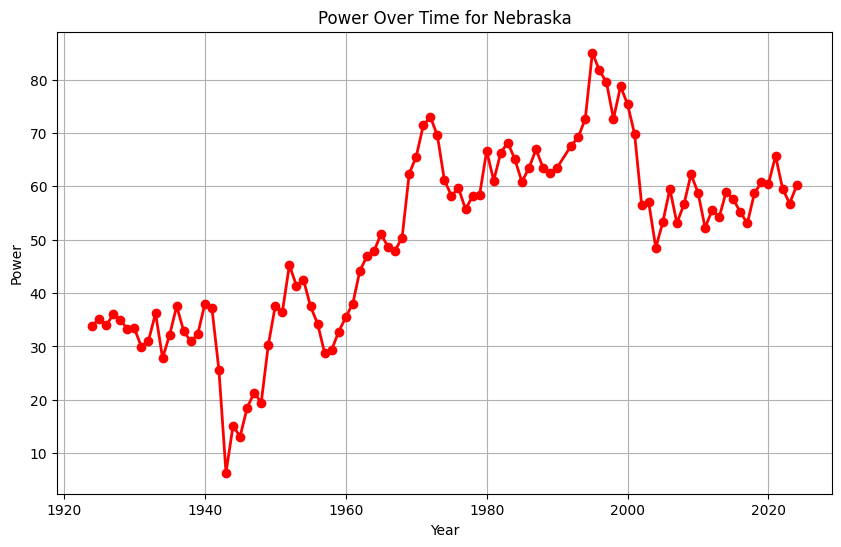

In [10]:
import pandas as pd
import matplotlib.pyplot as plt


# Filter the data for only the team "Nebraska"
neb_df = df[df['Team'] == 'Nebraska']

# Sort the data by Year to ensure the line plots chronologically
neb_sorted = neb_df.sort_values('Year')

# Set the size of the plot
plt.figure(figsize=(10, 6))

# Plot Year on the X-axis and Power on the Y-axis
plt.plot(neb_sorted['Year'], neb_sorted['Power'], marker='o', color='red', linewidth=2)

# Add titles, labels, and a grid for readability
plt.title('Power Over Time for Nebraska')
plt.xlabel('Year')
plt.ylabel('Power')
plt.grid(True)

# Display the plot
plt.show()

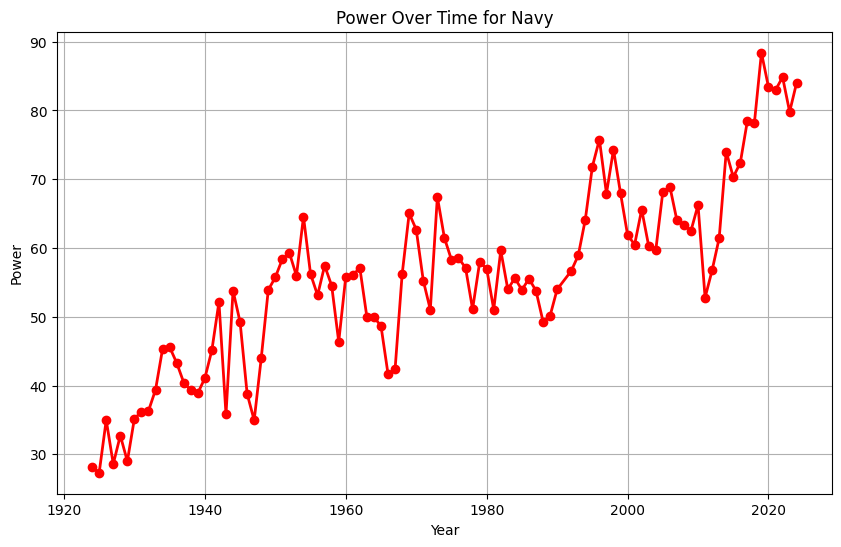

In [11]:
import pandas as pd
import matplotlib.pyplot as plt


# Filter the data for only the team "Navy"
navy_df = df[df['Team'] == 'Ohio St']

# Sort the data by Year to ensure the line plots chronologically
navy_sorted = navy_df.sort_values('Year')

# Set the size of the plot
plt.figure(figsize=(10, 6))

# Plot Year on the X-axis and Power on the Y-axis
plt.plot(navy_sorted['Year'], navy_sorted['Power'], marker='o', color='red', linewidth=2)

# Add titles, labels, and a grid for readability
plt.title('Power Over Time for Navy')
plt.xlabel('Year')
plt.ylabel('Power')
plt.grid(True)

# Display the plot
plt.show()

In [9]:

# 2. Identify teams with NO NaNs after 2000
years_after_2000 = [year for year in time_series_df.columns if int(year) > 2000]
df_post_2000 = time_series_df[years_after_2000]

# .dropna() without arguments drops any row with at least one NaN. 
# Getting the .index gives us the list of teams with complete data after 2000.
teams_with_no_nan_post_2000 = df_post_2000.dropna().index

# 3. Get columns from 1960 onwards
years_from_1960 = [year for year in time_series_df.columns if int(year) >= 1960]

# 4. Filter the dataframe using .loc[rows, columns]
df_filtered = time_series_df.loc[teams_with_no_nan_post_2000, years_from_1960]

# 5. Remove the mean of all teams for each year
# .mean(axis=0) calculates the average across all teams for each individual year
yearly_mean = df_filtered.mean(axis=0)

# Subtracting the yearly mean from the filtered dataframe
df_centered = df_filtered - yearly_mean

# View the results
display(df_centered.head())

print(f"Number of teams: {len(teams_with_no_nan_post_2000)}")



Year,1960,1961,1962,1963,1964,1965,1966,1967,1968,1969,...,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
Team,,,,,,,,,,,,,,,,,,,,,
Air Force,-6.194878,-10.997439,-5.398681,-0.303261,-1.56337,-0.803656,-0.938065,-4.815914,1.598511,8.643333,...,-0.607611,-1.563363,-6.504956,-3.62469,3.823009,2.425929,3.798673,2.701504,0.324602,-6.417611
Akron,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,-9.817611,-14.823363,-15.694956,-16.80469,-29.666991,-28.544071,-27.841327,-22.708496,-24.125398,-20.897611
Alabama,8.765122,17.272561,21.031319,17.406739,16.72663,19.166344,21.521935,14.574086,10.998511,9.483333,...,25.282389,28.576637,26.625044,29.04531,28.293009,33.715929,26.938673,27.531504,24.624602,21.992389
Arizona,-10.254878,-3.917439,-9.268681,-10.833261,-2.39337,-9.773656,-7.968065,-6.935914,-2.231489,-1.796667,...,4.122389,-5.323363,1.285044,-0.90469,-4.606991,-7.794071,-10.511327,-5.178496,8.764602,-3.107611
Arizona St,-6.004878,-4.577439,0.991319,-1.383261,0.32663,-5.313656,-2.578065,3.834086,8.428511,11.613333,...,6.662389,-1.063363,2.275044,3.58531,2.573009,6.995929,5.808673,-1.268496,-2.975398,8.542389


Number of teams: 113


Number of teams to plot: 113


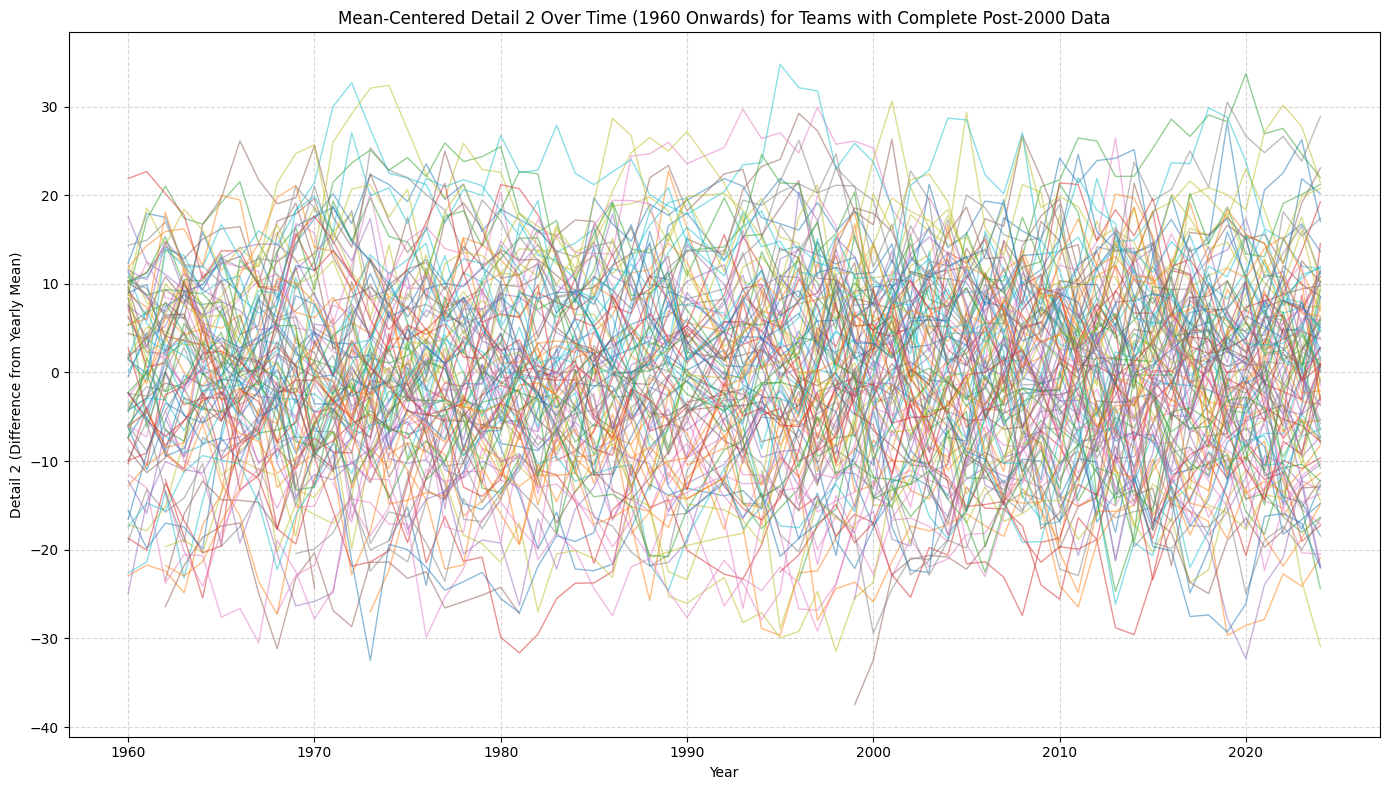

In [13]:
print("Number of teams to plot:", len(df_centered))

# Plot
plt.figure(figsize=(14, 8))
plt.plot(df_centered.columns, df_centered.T, alpha=0.5, linewidth=1)
plt.title('Mean-Centered Detail 2 Over Time (1960 Onwards) for Teams with Complete Post-2000 Data')
plt.xlabel('Year')
plt.ylabel('Detail 2 (Difference from Yearly Mean)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.savefig('all_teams_centered_plot.png')
plt.show()

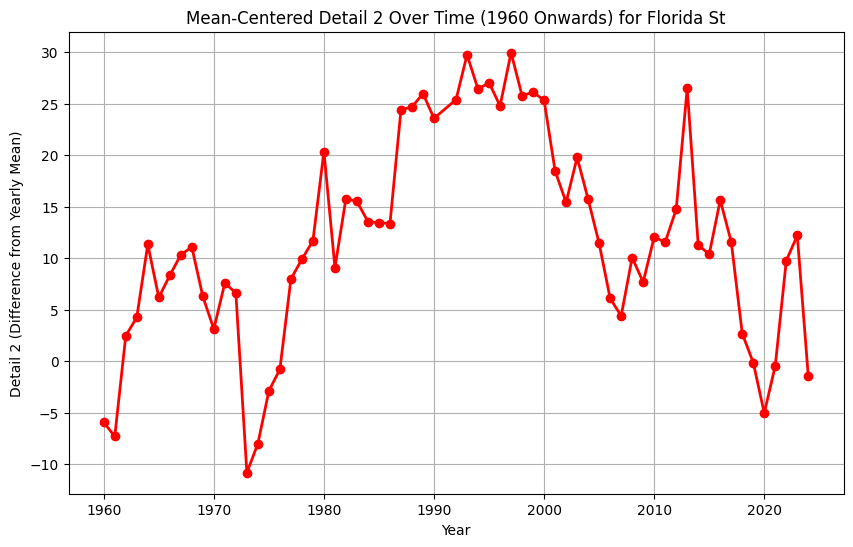

In [14]:
# 5. Extract Nebraska's data and plot it
if 'Nebraska' in df_centered.index:
    neb_data = df_centered.loc['Florida St']
    
    plt.figure(figsize=(10, 6))
    plt.plot(neb_data.index, neb_data.values, marker='o', color='red', linewidth=2)
    plt.title('Mean-Centered Detail 2 Over Time (1960 Onwards) for Florida St')
    plt.xlabel('Year')
    plt.ylabel('Detail 2 (Difference from Yearly Mean)')
    plt.grid(True)
    plt.savefig('nebraska_centered_plot.png')
    plt.show()
else:
    print("Nebraska is not in the filtered dataset (might have had NaNs post-2000).")

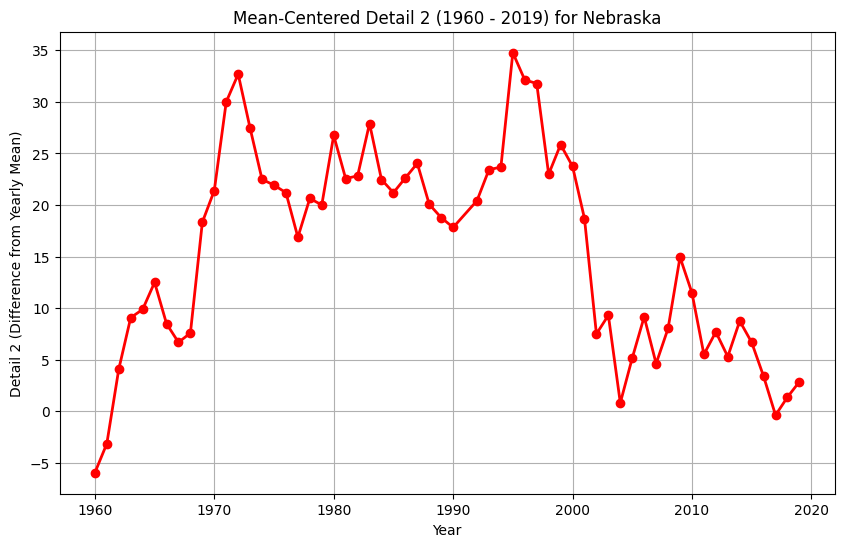

In [15]:
# 2. Identify teams with NO NaNs after 2000
years_after_2000 = [year for year in df_centered.columns if int(year) > 2000]
df_post_2000 = time_series_df[years_after_2000]
teams_with_no_nan_post_2000 = df_post_2000.dropna().index

# 3. Filter for years from 1960 to 2019 and for those specific teams
years_1960_to_2019 = [year for year in time_series_df.columns if 1960 <= int(year) <= 2019]
df_filtered_1960_2019 = time_series_df.loc[teams_with_no_nan_post_2000, years_1960_to_2019]

# 4. Remove the mean of all teams for each year
yearly_mean_1960_2019 = df_filtered_1960_2019.mean(axis=0)
df_centered_1960_2019 = df_filtered_1960_2019 - yearly_mean_1960_2019

# 5. Extract Nebraska's data and plot it
if 'Nebraska' in df_centered_1960_2019.index:
    neb_data = df_centered_1960_2019.loc['Nebraska']
    
    plt.figure(figsize=(10, 6))
    plt.plot(neb_data.index, neb_data.values, marker='o', color='red', linewidth=2)
    plt.title('Mean-Centered Detail 2 (1960 - 2019) for Nebraska')
    plt.xlabel('Year')
    plt.ylabel('Detail 2 (Difference from Yearly Mean)')
    plt.grid(True)
    plt.show()

In [4]:
import pandas as pd
import numpy as np
import warnings
from statsmodels.tsa.arima.model import ARIMA
from sklearn.metrics import mean_squared_error

# Suppress convergence warnings that occur when fitting high lags on small datasets
warnings.filterwarnings("ignore")

# 1. Load, filter, and center the data
df = pd.read_csv("massey_ratings.csv")
time_series_df = df.pivot_table(index='Team', columns='Year', values='Detail 2')

# Filter for teams with complete data post-2000
years_after_2000 = [year for year in time_series_df.columns if int(year) > 2000]
teams_with_no_nan = time_series_df[years_after_2000].dropna().index

# Filter for the 1960 to 2019 window and mean-center
years_1960_to_2019 = [year for year in time_series_df.columns if 1960 <= int(year) <= 2019]
df_filtered = time_series_df.loc[teams_with_no_nan, years_1960_to_2019]
df_centered = df_filtered - df_filtered.mean(axis=0)

# 2. Split data into Train (1960-1999) and Test (2000-2019)
train_cols = [y for y in df_centered.columns if 1960 <= int(y) < 2000]
test_cols = [y for y in df_centered.columns if 2000 <= int(y) <= 2019]

print(f"Training years: {len(train_cols)}")
print(f"Testing years: {len(test_cols)}\n")

# 3. Loop through varying AR coefficients from 1 to 15
for p in range(1, 16):
    team_errors = []
    team_ar_coefs = []
    
    for team in df_centered.index:
        train_data = df_centered.loc[team, train_cols].values
        test_data = df_centered.loc[team, test_cols].values
        
        # Skip team if they have missing historical data in the training period
        if np.isnan(train_data).any() or np.isnan(test_data).any():
            continue
            
        try:
            # Fit the ARIMA(p, 1, 1) model
            model = ARIMA(train_data, order=(p, 1, 1), 
                          enforce_stationarity=False, 
                          enforce_invertibility=False)
            model_fit = model.fit()
            
            # Forecast the test period
            predictions = model_fit.forecast(steps=len(test_data))
            
            # Calculate RMSE
            rmse = np.sqrt(mean_squared_error(test_data, predictions))
            team_errors.append(rmse)
            
            # Store the AR coefficients (phi_1, ..., phi_p)
            team_ar_coefs.append(model_fit.arparams)
        except Exception:
            continue
            
    # Print the average error, number of teams, and average phi values
    if team_errors:
        avg_error = np.mean(team_errors)
        num_teams = len(team_errors)
        avg_phis = np.mean(team_ar_coefs, axis=0)
        phi_str = ", ".join([f"phi_{i+1}={val:.4f}" for i, val in enumerate(avg_phis)])
        print(f"ARIMA({p}, 1, 1) | Teams: {num_teams} | Avg RMSE: {avg_error:.4f} | Avg Phis: [{phi_str}]")
    else:
        print(f"ARIMA({p}, 1, 1) - Failed to fit across all teams")


Training years: 39
Testing years: 20

ARIMA(1, 1, 1) | Teams: 80 | Avg RMSE: 8.8114 | Avg Phis: [phi_1=0.1732]
ARIMA(2, 1, 1) | Teams: 80 | Avg RMSE: 8.5428 | Avg Phis: [phi_1=-0.0011, phi_2=-0.1549]
ARIMA(3, 1, 1) | Teams: 80 | Avg RMSE: 8.6452 | Avg Phis: [phi_1=0.0192, phi_2=-0.1378, phi_3=-0.0984]
ARIMA(4, 1, 1) | Teams: 80 | Avg RMSE: 8.6245 | Avg Phis: [phi_1=-0.1359, phi_2=-0.1681, phi_3=-0.1223, phi_4=-0.1048]
ARIMA(5, 1, 1) | Teams: 80 | Avg RMSE: 8.8657 | Avg Phis: [phi_1=-0.0920, phi_2=-0.1555, phi_3=-0.1140, phi_4=-0.1005, phi_5=-0.0421]
ARIMA(6, 1, 1) | Teams: 80 | Avg RMSE: 8.7070 | Avg Phis: [phi_1=-0.0152, phi_2=-0.1760, phi_3=-0.1005, phi_4=-0.1041, phi_5=-0.0437, phi_6=-0.1408]
ARIMA(7, 1, 1) | Teams: 80 | Avg RMSE: 8.6061 | Avg Phis: [phi_1=-0.0788, phi_2=-0.1700, phi_3=-0.0958, phi_4=-0.0914, phi_5=-0.0622, phi_6=-0.1255, phi_7=-0.0617]
ARIMA(8, 1, 1) | Teams: 80 | Avg RMSE: 8.6306 | Avg Phis: [phi_1=-0.0881, phi_2=-0.1870, phi_3=-0.1185, phi_4=-0.1090, phi_5=-0.086

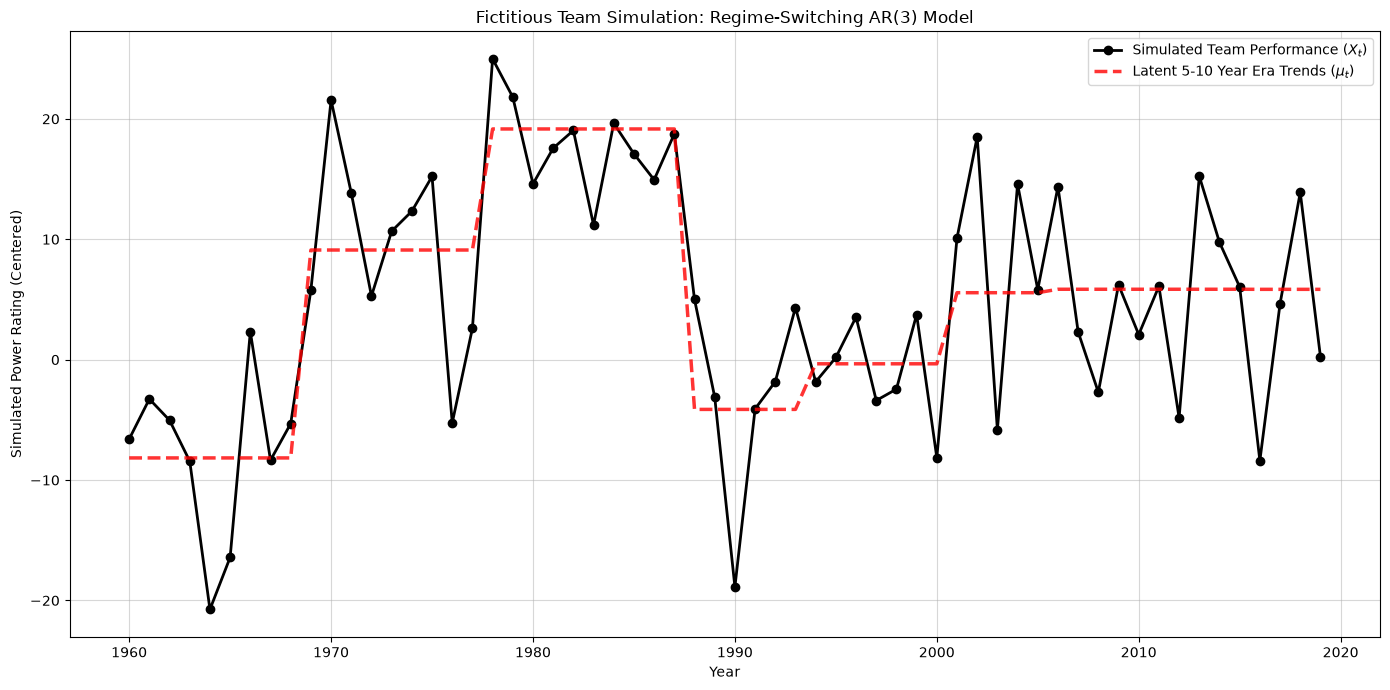

In [ ]:


import numpy as np
import matplotlib.pyplot as plt

np.random.seed(112) # Seeded for a visually clear example
n_years = 60
years = np.arange(1960, 2020)

# 1. Generate the 5-10 year regime trends (Latent Baseline)
mu_t = np.zeros(n_years)
current_year = 0

while current_year < n_years:
    # Pick a random era duration between 5 and 10 years
    duration = np.random.randint(5, 11) 
    
    # Draw a new baseline performance level for this era
    # scale=8 maps to the variance we observed in historical team baselines
    regime_level = np.random.normal(loc=0, scale=8) 
    
    end_year = min(current_year + duration, n_years)
    mu_t[current_year:end_year] = regime_level
    current_year = end_year

# 2. Generate the AR(3) fluctuations around the baseline
# Using typical coefficients observed across the 113 historical teams
#phi_1, phi_2, phi_3 =0.0192, -0.1378, -0.0984 #Average Phi
phi_1, phi_2, phi_3 = 0.55, 0.20, 0.10 #Typical phi

# Match the ~8.4 average RMSE seen in earlier tests
sigma_epsilon = 6.0 

z_t = np.zeros(n_years)
epsilon = np.random.normal(0, sigma_epsilon, n_years)

# Initialize the first 3 years with random noise
z_t[0:3] = epsilon[0:3]

# Apply the AR(3) memory
for t in range(3, n_years):
    z_t[t] = phi_1 * z_t[t-1] + phi_2 * z_t[t-2] + phi_3 * z_t[t-3] + epsilon[t]

# 3. Combine into the final simulated series
X_t = mu_t + z_t

# 4. Plotting
plt.figure(figsize=(14, 7))
plt.plot(years, X_t, label='Simulated Team Performance ($X_t$)', color='black', marker='o', linewidth=2)
plt.plot(years, mu_t, label='Latent 5-10 Year Era Trends ($\mu_t$)', color='red', linestyle='--', linewidth=2.5, alpha=0.8)

plt.title('Fictitious Team Simulation: Regime-Switching AR(3) Model')
plt.xlabel('Year')
plt.ylabel('Simulated Power Rating (Centered)')
plt.legend()
plt.grid(True, alpha=0.5)
plt.tight_layout()
plt.show()

Number of teams to plot: 81
Variance K-S Test: statistic=0.1481, p-value=0.3380
Lag-1 ACF K-S Test: statistic=0.1728, p-value=0.1783


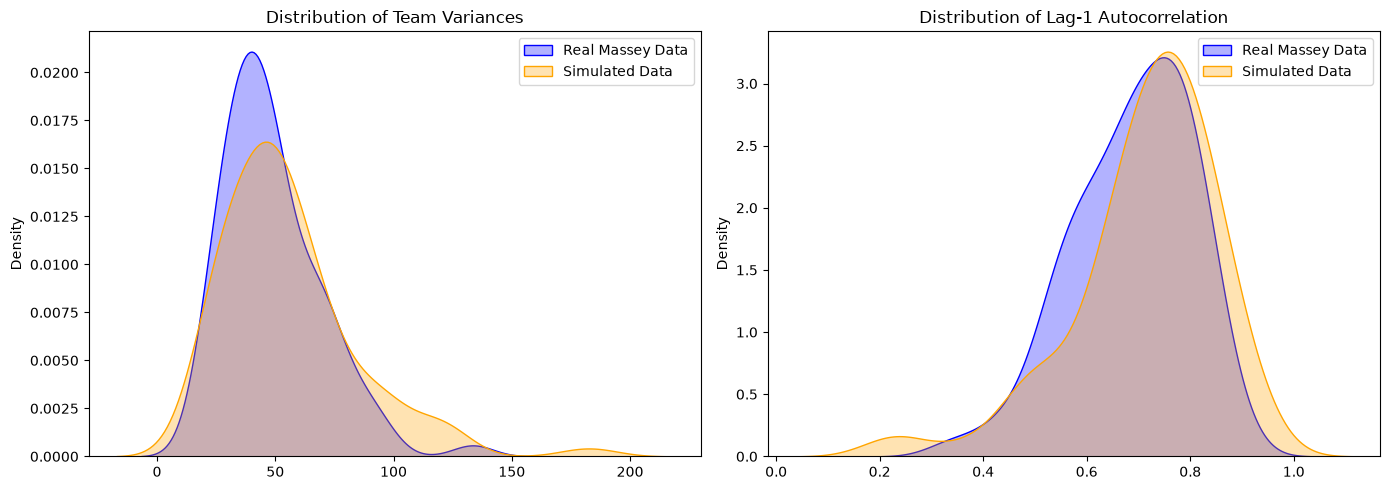

In [11]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import ks_2samp

# 1. Define the Simulation Model
def simulate_team(n_years=60):
    mu_step = np.zeros(n_years)
    current_year = 0
    while current_year < n_years:
        duration = np.random.randint(5, 11) 
        regime_level = np.random.normal(loc=0, scale=5) #typical
        end_year = min(current_year + duration, n_years)
        mu_step[current_year:end_year] = regime_level
        current_year = end_year
    
    alpha = 0.4 
    mu_smoothed = np.zeros(n_years)
    mu_smoothed[0] = mu_step[0]
    for t in range(1, n_years):
        mu_smoothed[t] = alpha * mu_step[t] + (1 - alpha) * mu_smoothed[t-1]
    
    #phi_1, phi_2, phi_3 =0.0192, -0.1378, -0.0984
    phi_1, phi_2, phi_3 = 0.55, 0.20, 0.10 #typical
    z_t = np.zeros(n_years)
    epsilon = np.random.normal(0, 4.5, n_years)
    z_t[0:3] = epsilon[0:3]
    for t in range(3, n_years):
        z_t[t] = phi_1 * z_t[t-1] + phi_2 * z_t[t-2] + phi_3 * z_t[t-3] + epsilon[t]
    
    return mu_smoothed + z_t

# 2. Load Your Real Data
df = pd.read_csv("massey_ratings.csv")
time_series_df = df.pivot_table(index='Team', columns='Year', values='Detail 2')
years_1960_to_2019 = [year for year in time_series_df.columns if 1960 <= int(year) <= 2019]

# Clean and center
real_df = time_series_df[years_1960_to_2019].dropna()

print("Number of teams to plot:", len(real_df))

real_data = (real_df - real_df.mean(axis=0)).values

# Generate matching simulated batch
n_teams = real_data.shape[0]
sim_data = np.array([simulate_team() for _ in range(n_teams)])
sim_data = sim_data - np.mean(sim_data, axis=0)

# 3. Extract Features for Distribution Testing
def get_features(data_matrix):
    variances = np.var(data_matrix, axis=1)
    lag1_acf = [np.corrcoef(row[:-1], row[1:])[0, 1] for row in data_matrix]
    return variances, np.array(lag1_acf)

real_var, real_acf = get_features(real_data)
sim_var, sim_acf = get_features(sim_data)

# 4. Run Two-Sample K-S Tests
ks_var = ks_2samp(real_var, sim_var)
ks_acf = ks_2samp(real_acf, sim_acf)

print(f"Variance K-S Test: statistic={ks_var.statistic:.4f}, p-value={ks_var.pvalue:.4f}")
print(f"Lag-1 ACF K-S Test: statistic={ks_acf.statistic:.4f}, p-value={ks_acf.pvalue:.4f}")

# 5. Plot Overlays
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.kdeplot(real_var, ax=axes[0], label='Real Massey Data', color='blue', fill=True, alpha=0.3)
sns.kdeplot(sim_var, ax=axes[0], label='Simulated Data', color='orange', fill=True, alpha=0.3)
axes[0].set_title('Distribution of Team Variances')
axes[0].legend()

sns.kdeplot(real_acf, ax=axes[1], label='Real Massey Data', color='blue', fill=True, alpha=0.3)
sns.kdeplot(sim_acf, ax=axes[1], label='Simulated Data', color='orange', fill=True, alpha=0.3)
axes[1].set_title('Distribution of Lag-1 Autocorrelation')
axes[1].legend()

plt.tight_layout()
plt.show()

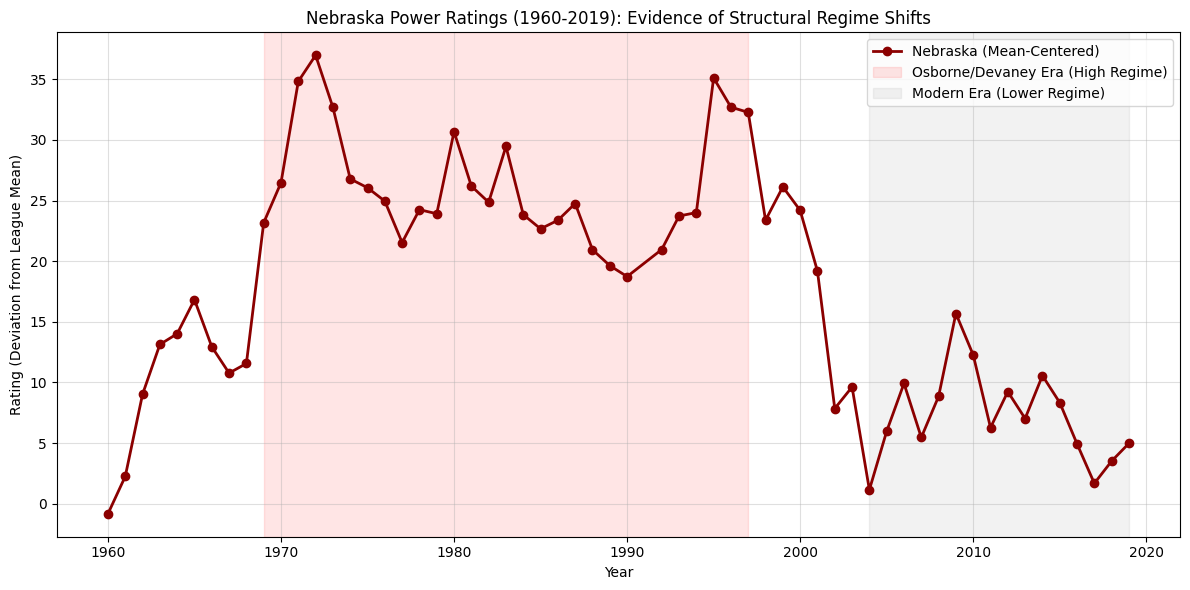

In [18]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")

try:
    df = pd.read_csv("massey_ratings.csv")
    time_series_df = df.pivot_table(index='Team', columns='Year', values='Detail 2')
    years_1960_to_2019 = [year for year in time_series_df.columns if 1960 <= int(year) <= 2019]
    nebraska_data = time_series_df.loc['Nebraska', years_1960_to_2019]
    nebraska_centered = nebraska_data - time_series_df[years_1960_to_2019].mean(axis=0)

    plt.figure(figsize=(12, 6))
    years = [int(y) for y in years_1960_to_2019]
    plt.plot(years, nebraska_centered.values, color='darkred', marker='o', linewidth=2, label='Nebraska (Mean-Centered)')
    
    # Add a rough regime span for visual context (e.g., 70s-90s dominance vs modern era)
    plt.axvspan(1969, 1997, color='red', alpha=0.1, label='Osborne/Devaney Era (High Regime)')
    plt.axvspan(2004, 2019, color='gray', alpha=0.1, label='Modern Era (Lower Regime)')
    
    plt.title("Nebraska Power Ratings (1960-2019): Evidence of Structural Regime Shifts")
    plt.xlabel("Year")
    plt.ylabel("Rating (Deviation from League Mean)")
    plt.legend()
    plt.grid(True, alpha=0.4)
    plt.tight_layout()
    plt.savefig('nebraska_regime_need.png')
except Exception as e:
    print(f"Error: {e}")